Dataset Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Information


,Column,Data Type,Missing Values,Unique Values
CustomerID,CustomerID,int64,0,200
Gender,Gender,str,0,2
Age,Age,int64,0,51
Annual Income (k$),Annual Income (k$),int64,0,64
Spending Score (1-100),Spending Score (1-100),int64,0,84



Descriptive Statistics


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



Numerical Columns: ['CustomerID', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']
Categorical Columns: ['Gender']


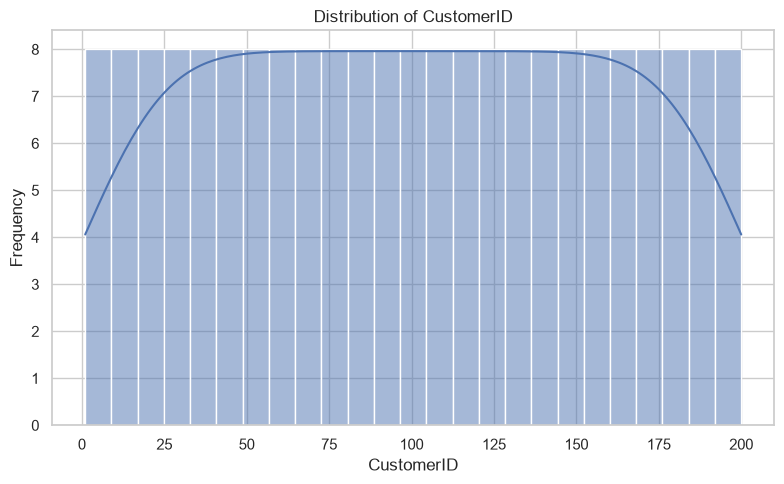

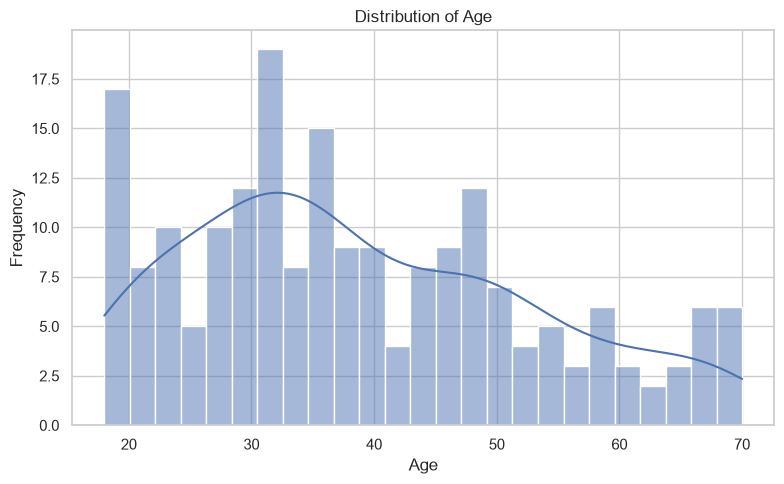

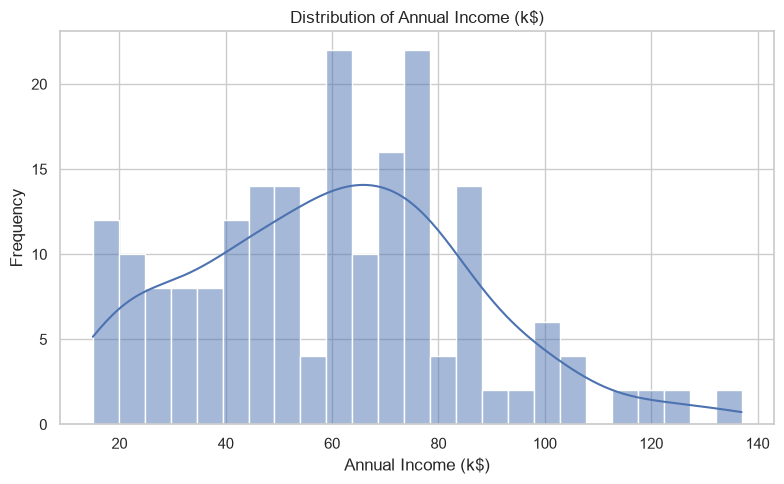

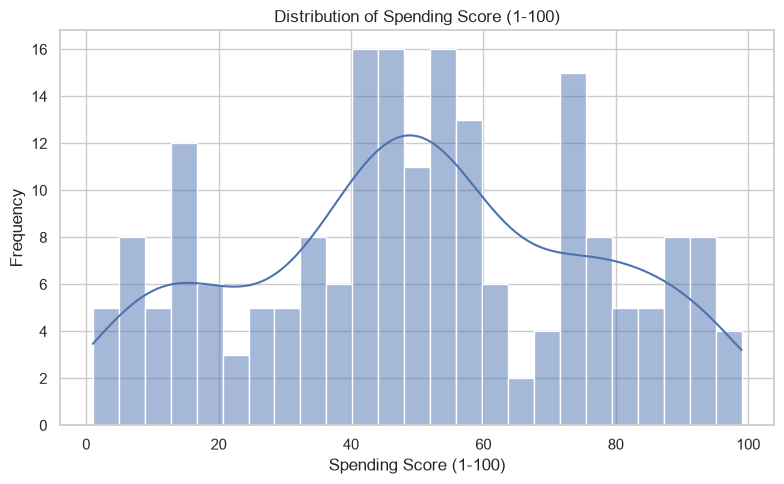

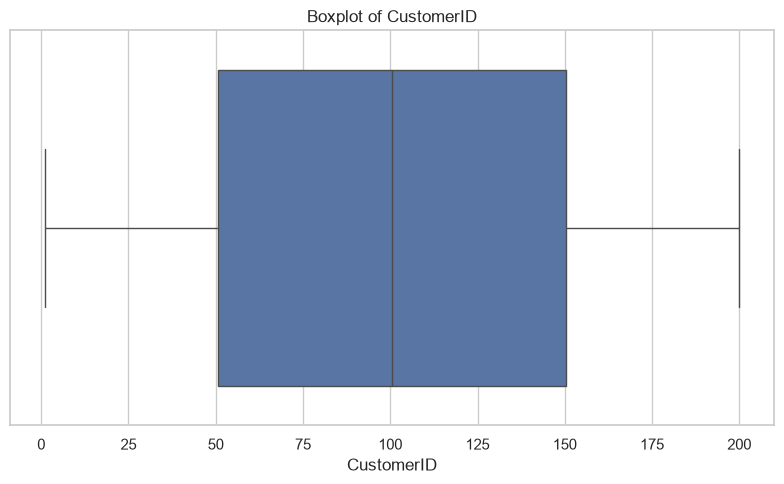

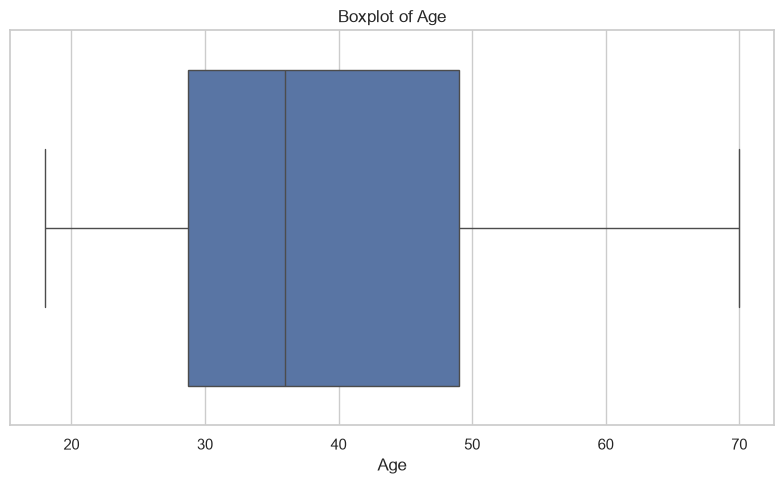

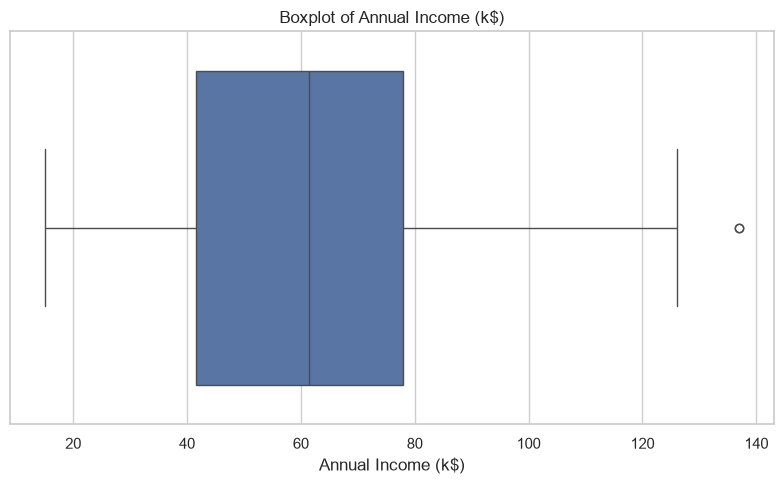

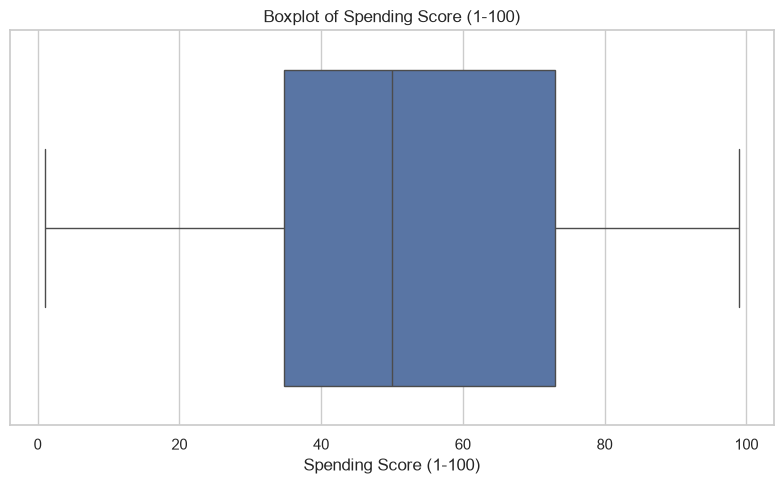

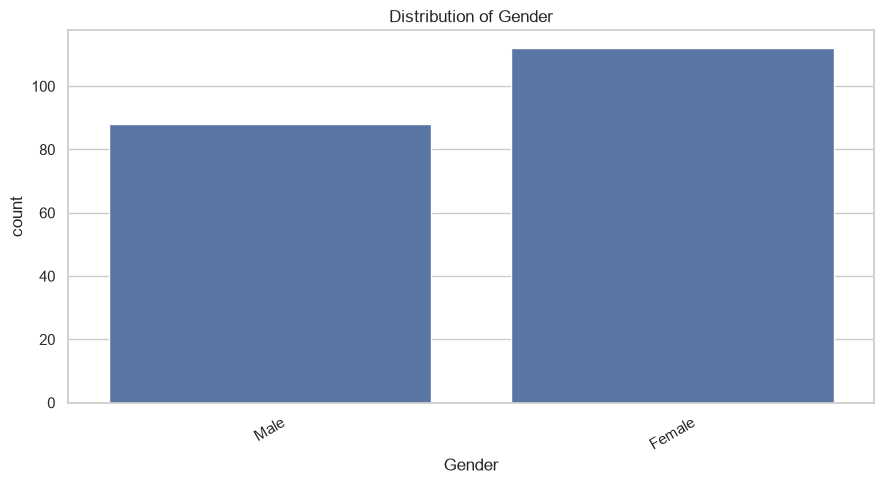

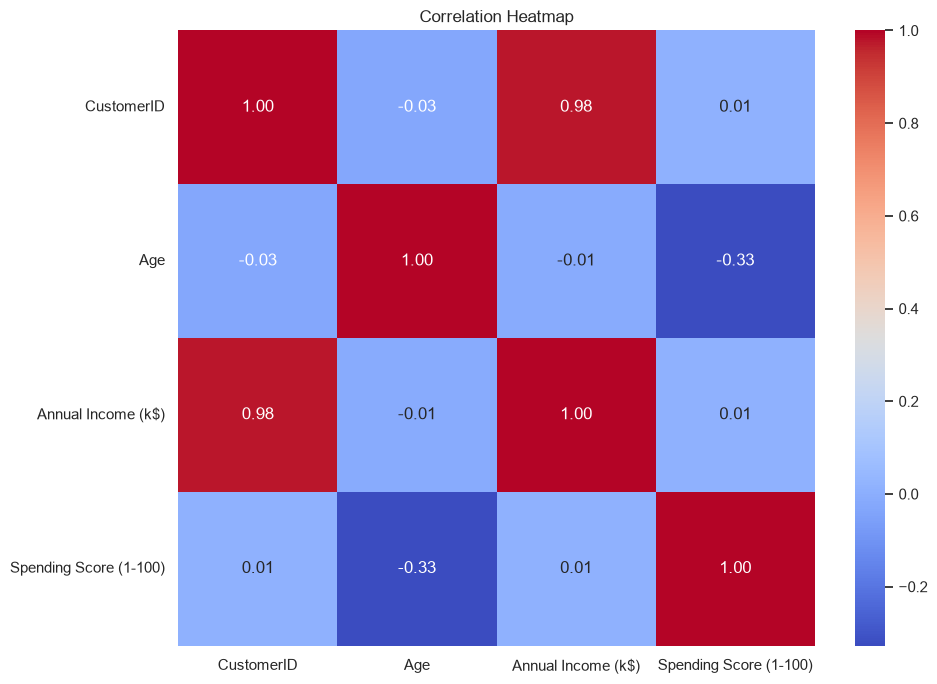

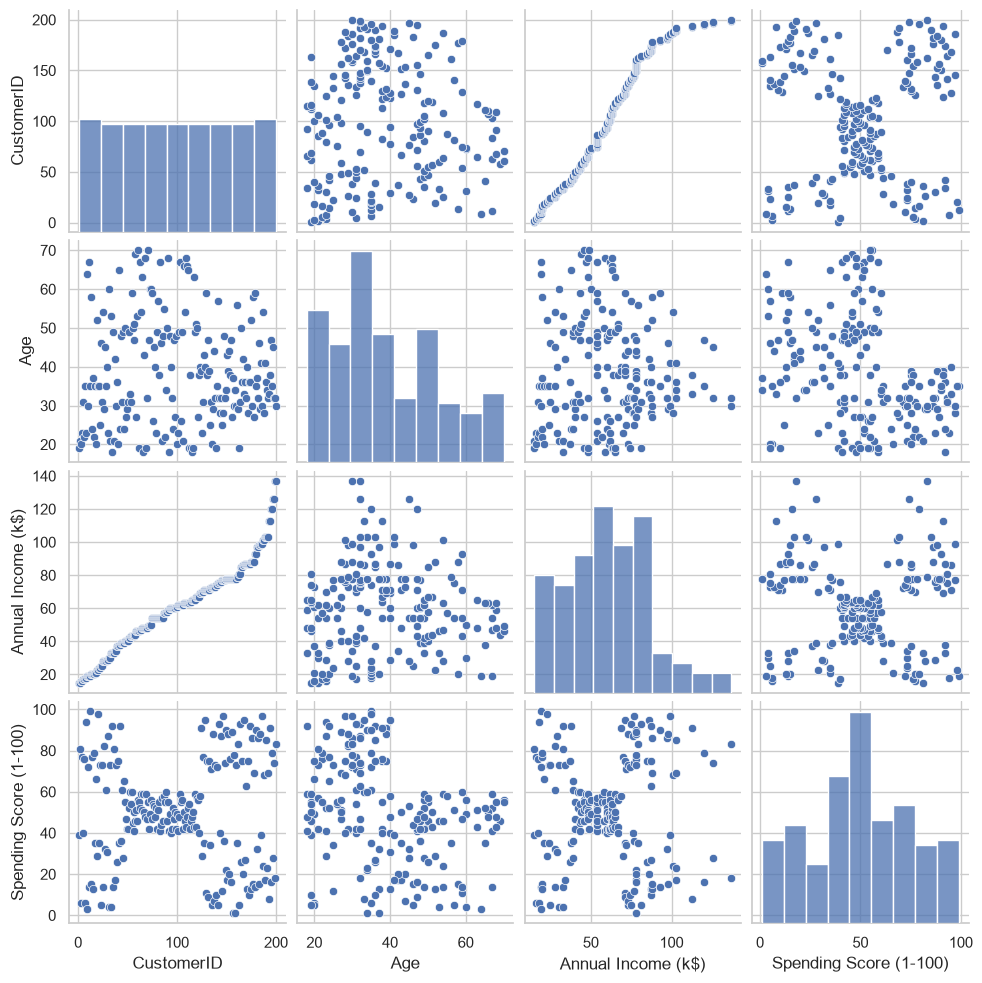


Features Used for Hierarchical Clustering:
['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Scaled Feature Matrix Shape: (200, 3)


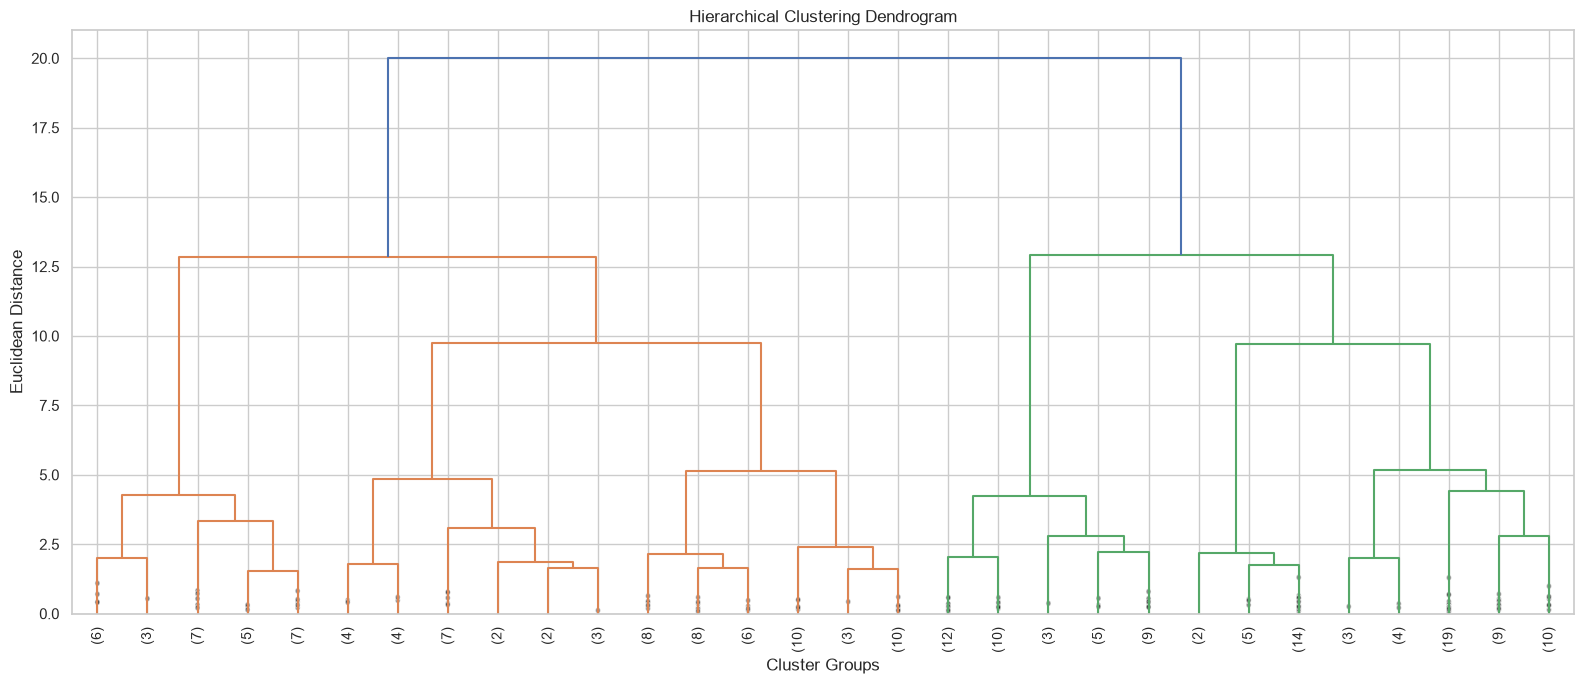

,K,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,2,0.317957,99.000668,1.308296
1,3,0.321489,88.101741,1.127729
2,4,0.361451,102.019399,1.016382
3,5,0.390028,107.826560,0.916289
4,6,0.420117,127.986454,0.852102
5,7,0.398295,120.686805,0.851329
6,8,0.366479,118.066796,0.841587
7,9,0.375385,117.475123,0.858235
8,10,0.380889,117.221895,0.885471


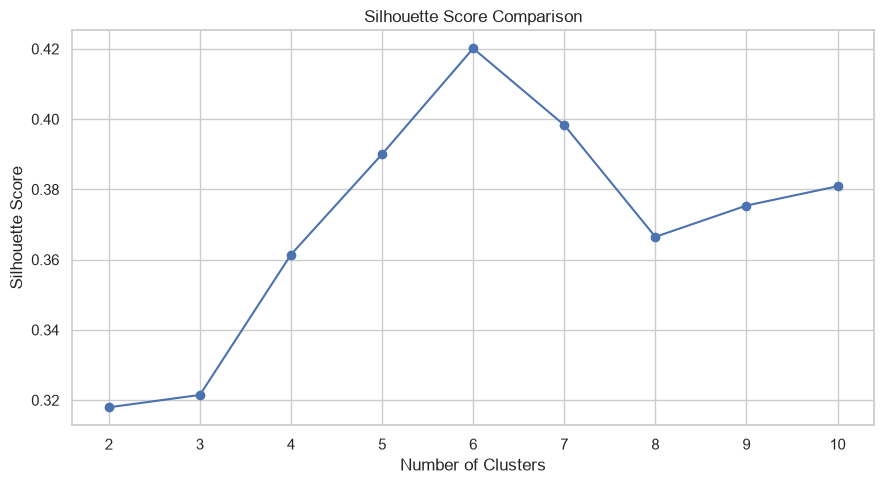

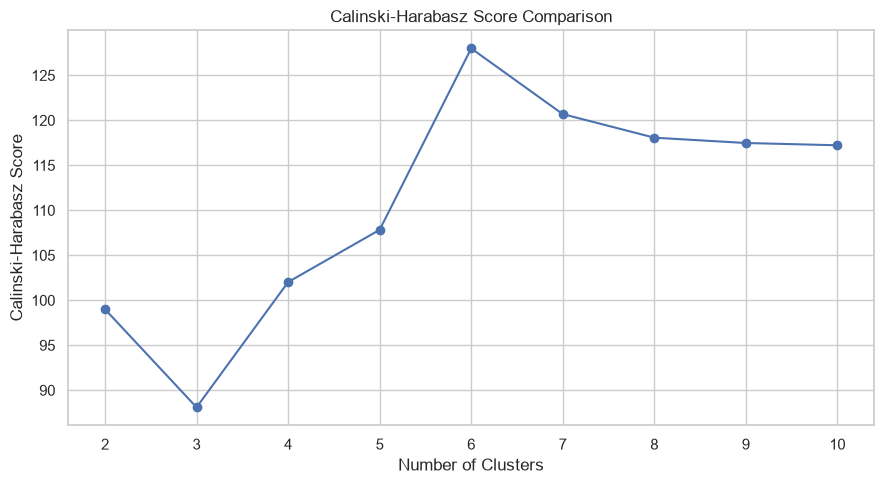

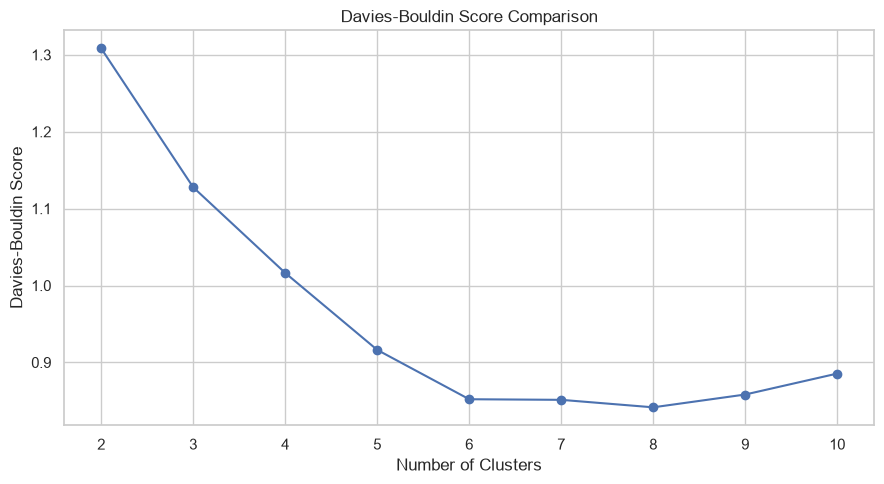

Optimal Number of Clusters: 6

Cluster Counts


,Customers
Cluster,
0,45
1,45
2,39
3,28
4,22
5,21


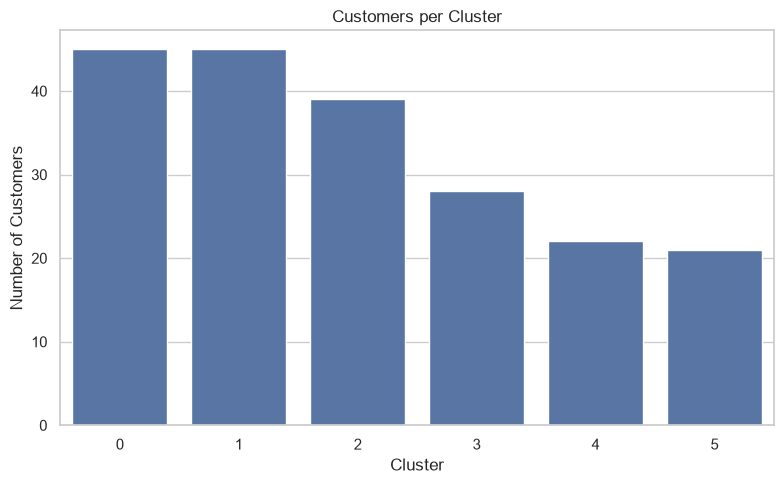

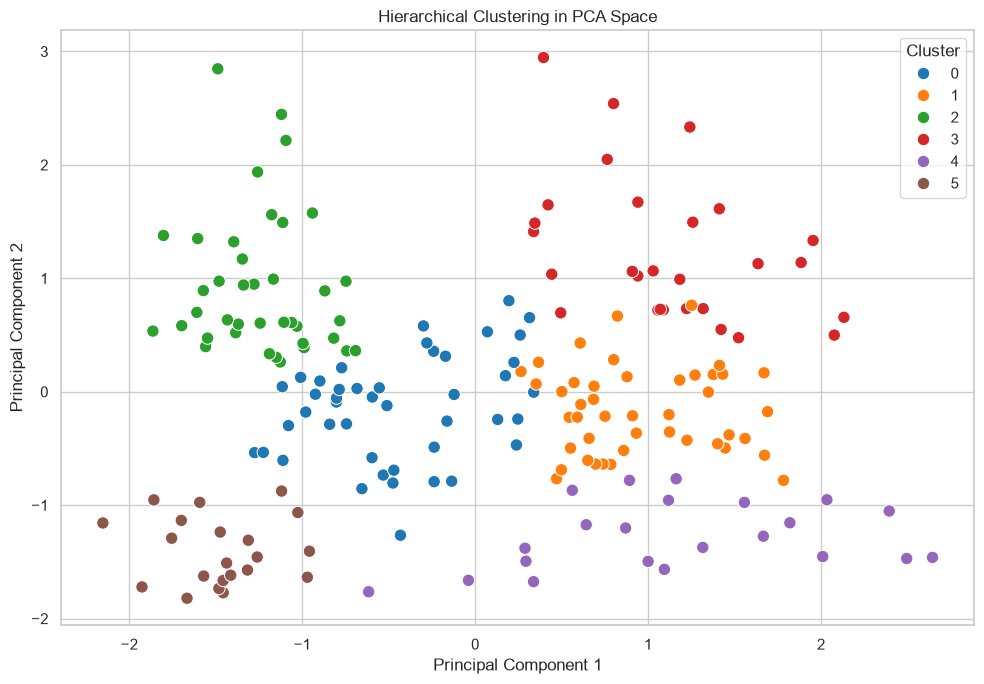

,Number of Clusters,Silhouette Score,Calinski-Harabasz Score,Davies-Bouldin Score
0,6,0.420117,127.986454,0.852102


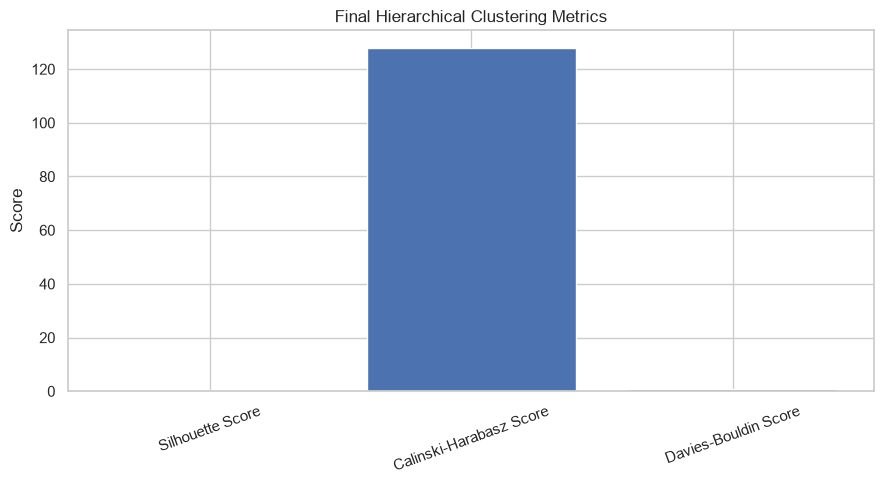

Age                           Annual Income (k$)         \
              mean median        std min max               mean median   
Cluster                                                                  
0        27.377778   26.0   7.758540  18  45          57.511111   60.0   
1        56.400000   54.0   8.373117  43  70          55.288889   54.0   
2        32.692308   32.0   3.728650  27  40          86.538462   79.0   
3        43.892857   43.5   8.337063  32  59          91.285714   87.0   
4        44.318182   45.5  12.800247  19  67          25.772727   24.5   
5        24.809524   23.0   4.905294  18  35          25.619048   24.0   

                            Spending Score (1-100)                            
               std min  max                   mean median        std min max  
Cluster                                                                       
0        11.750478  28   81              45.844444   50.0  14.108275   5  61  
1         9.834129  38   79              48.355556   48.0   6.869417  35  60  
2        16.312485  69  137              82.128205   83.0   9.364489  63  97  
3        16.915601  71  137              16.678571   16.0   8.973432   1  39  
4         7.646548  15   39              20.272727   16.0  12.947446   3  40  
5         7.736124  15   39              80.238095   77.0   9.909111  65  99

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,27.377778,57.511111,45.844444
1,56.400000,55.288889,48.355556
2,32.692308,86.538462,82.128205
3,43.892857,91.285714,16.678571
4,44.318182,25.772727,20.272727
5,24.809524,25.619048,80.238095


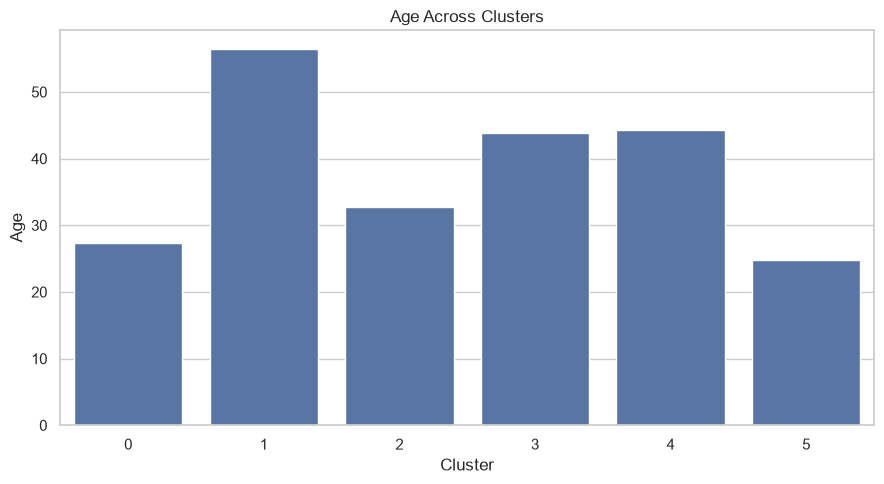

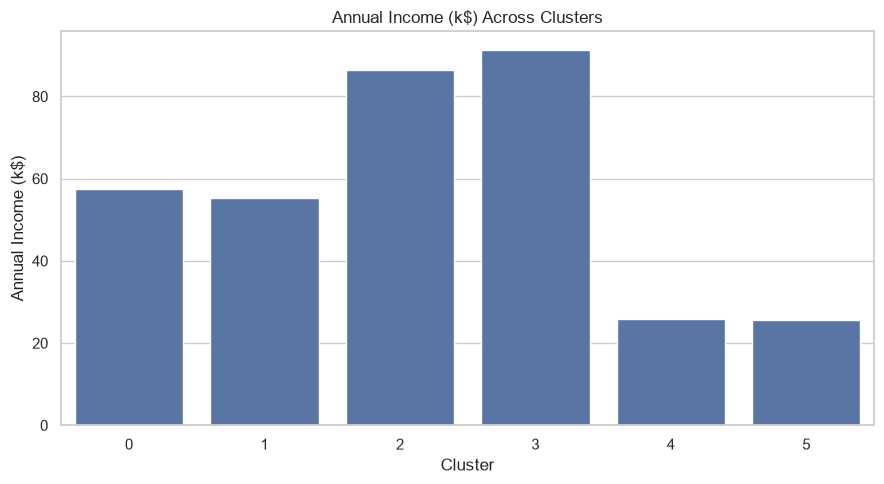

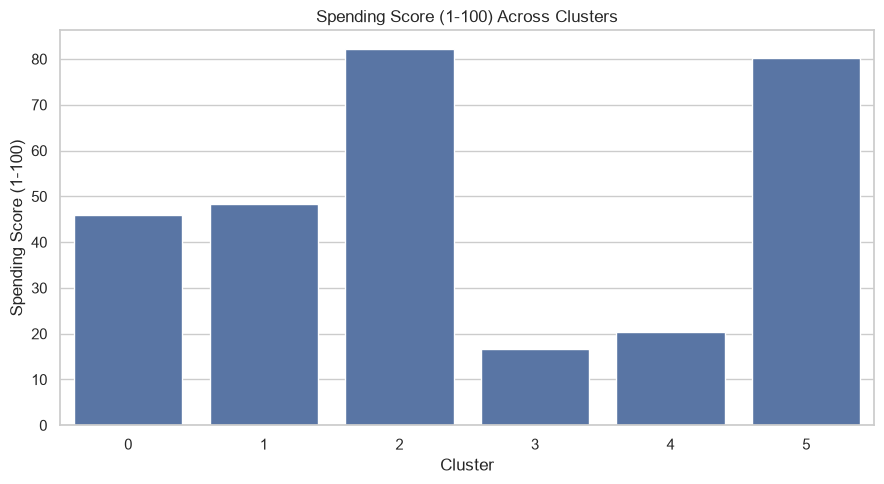

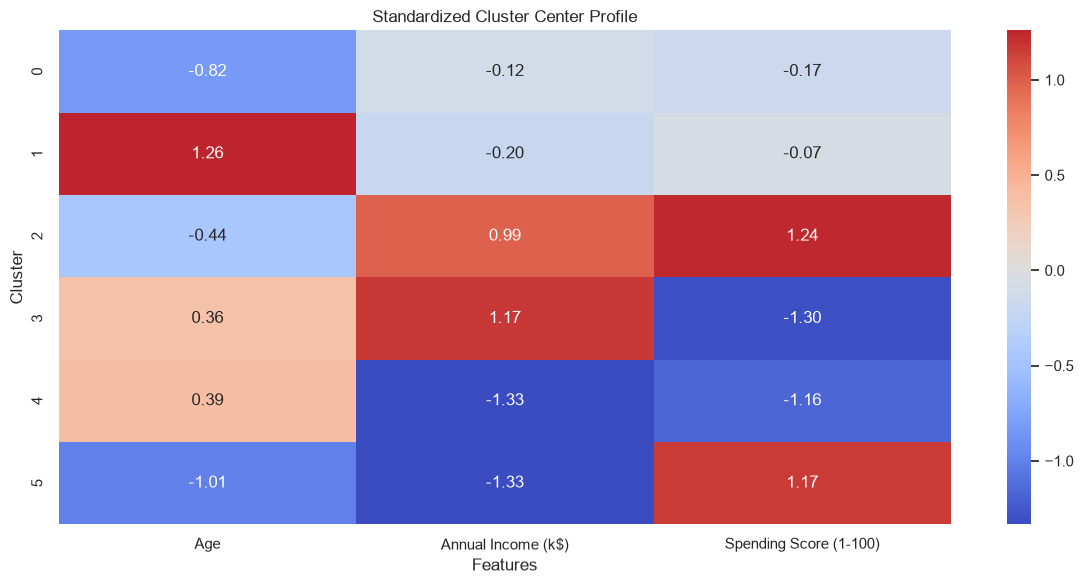

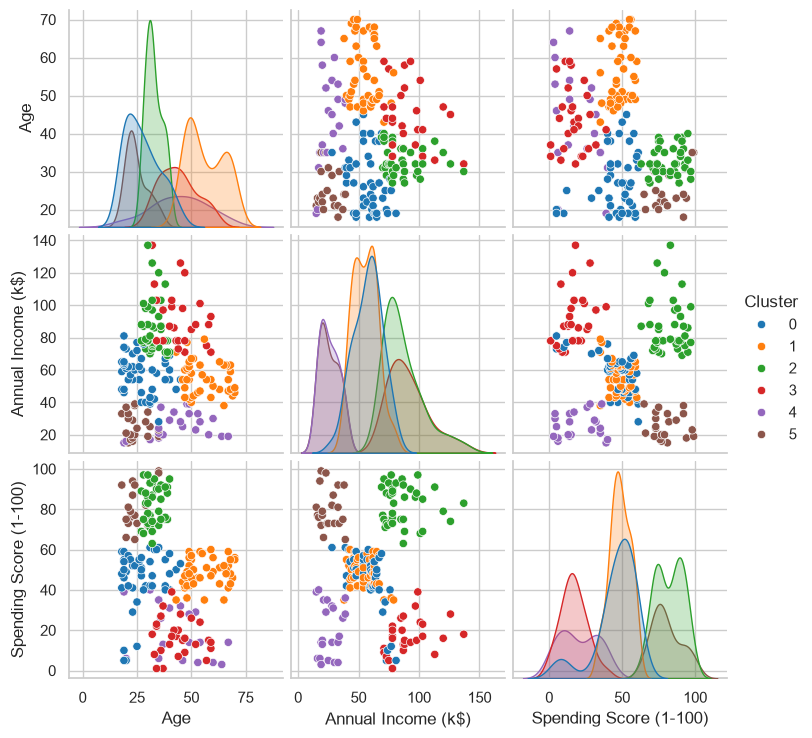


Gender Distribution Across Clusters (%)


Gender,Female,Male
Cluster,,
0,60.00,40.00
1,53.33,46.67
2,53.85,46.15
3,50.00,50.00
4,59.09,40.91
5,61.90,38.10


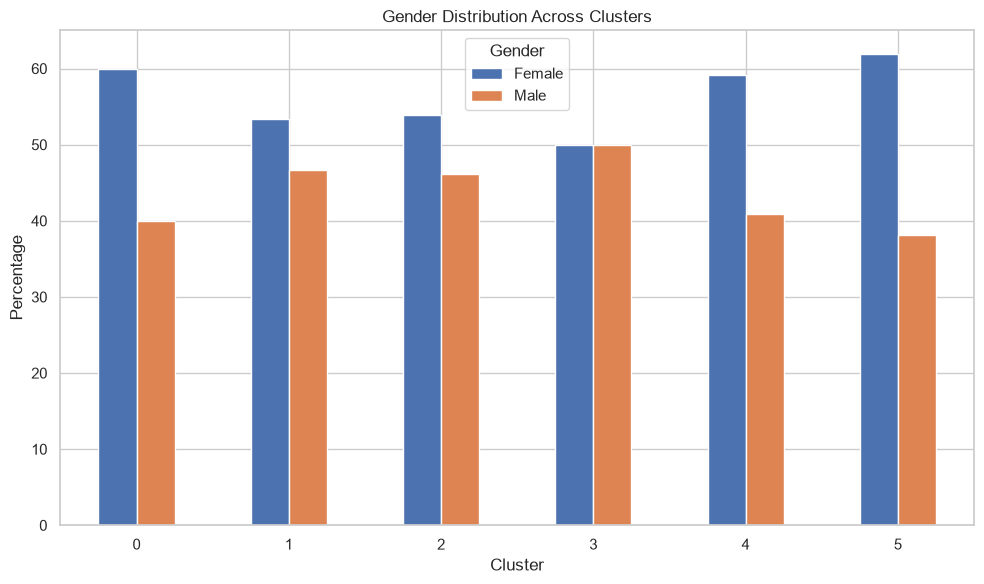

,Cluster,Percentage
0,0,22.5
1,1,22.5
2,2,19.5
3,3,14.0
4,4,11.0
5,5,10.5


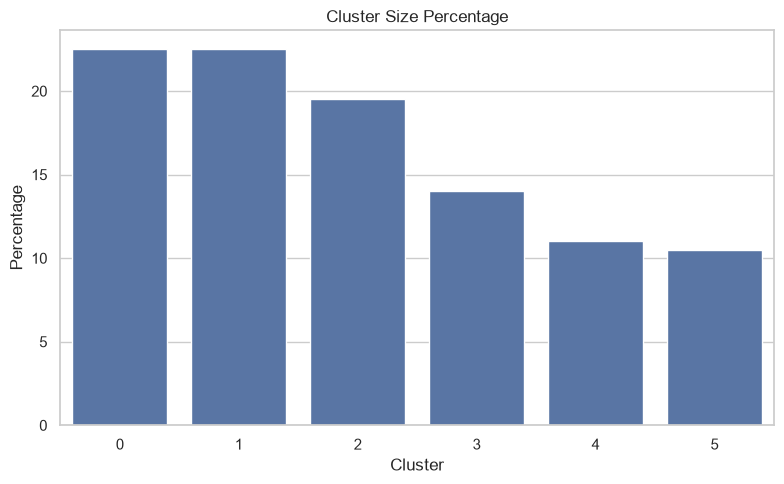

Files exported successfully.

Final Hierarchical Clustering Summary
Optimal K: 6
Silhouette Score: 0.4201
Calinski-Harabasz Score: 127.9865
Davies-Bouldin Score: 0.8521

Cluster Distribution:


,Customers
Cluster,
0,45
1,45
2,39
3,28
4,22
5,21


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

file_paths = [
    "/kaggle/input/mall-customers/Mall_Customers.csv",
    "/kaggle/input/mall-customers/Mall_Customers.csv",
    "Mall_Customers.csv",
    "/mnt/data/Mall_Customers.csv"
]

file_path = None

for path in file_paths:
    if os.path.exists(path):
        file_path = path
        break

if file_path is None:
    for root in ["/kaggle/input", "/mnt/data"]:
        if os.path.exists(root):
            for root_dir, dirs, files in os.walk(root):
                for file in files:
                    if file.lower() == "mall_customers.csv":
                        file_path = os.path.join(root_dir, file)
                        break
                if file_path:
                    break
        if file_path:
            break

if file_path is None:
    raise FileNotFoundError("Mall_Customers.csv not found.")

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
display(df.head())

print("\nDataset Information")
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str),
    "Missing Values": df.isnull().sum(),
    "Unique Values": df.nunique()
}))

print("\nDescriptive Statistics")
display(df.describe(include="all").T)

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical Columns:", numeric_cols)
print("Categorical Columns:", categorical_cols)

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True, bins=25)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

for col in categorical_cols:
    if df[col].nunique() <= 15:
        plt.figure(figsize=(9, 5))
        sns.countplot(data=df, x=col)
        plt.title(f"Distribution of {col}")
        plt.xticks(rotation=30)
        plt.tight_layout()
        plt.show()

if len(numeric_cols) > 1:
    plt.figure(figsize=(10, 7))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

if len(numeric_cols) >= 2:
    sns.pairplot(df[numeric_cols])
    plt.show()

id_candidates = [
    "customerid",
    "customer_id",
    "customer id",
    "id",
    "unnamed: 0"
]

drop_cols = []

for col in df.columns:
    normalized = col.lower().strip()
    if normalized in id_candidates:
        drop_cols.append(col)
    elif df[col].nunique() == len(df):
        drop_cols.append(col)

feature_cols = [col for col in numeric_cols if col not in drop_cols]

print("\nFeatures Used for Hierarchical Clustering:")
print(feature_cols)

X = df[feature_cols].copy()

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nScaled Feature Matrix Shape:", X_scaled.shape)

linkage_matrix = linkage(X_scaled, method="ward")

plt.figure(figsize=(16, 7))
dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True
)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster Groups")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

results = []

for k in range(2, 11):
    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_scaled)

    results.append({
        "K": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin Score": davies_bouldin_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(results)

display(metrics_df)

plt.figure(figsize=(9, 5))
plt.plot(
    metrics_df["K"],
    metrics_df["Silhouette Score"],
    marker="o"
)
plt.title("Silhouette Score Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.xticks(metrics_df["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    metrics_df["K"],
    metrics_df["Calinski-Harabasz Score"],
    marker="o"
)
plt.title("Calinski-Harabasz Score Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Calinski-Harabasz Score")
plt.xticks(metrics_df["K"])
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    metrics_df["K"],
    metrics_df["Davies-Bouldin Score"],
    marker="o"
)
plt.title("Davies-Bouldin Score Comparison")
plt.xlabel("Number of Clusters")
plt.ylabel("Davies-Bouldin Score")
plt.xticks(metrics_df["K"])
plt.tight_layout()
plt.show()

final_k = int(
    metrics_df.loc[
        metrics_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Optimal Number of Clusters:", final_k)

final_model = AgglomerativeClustering(
    n_clusters=final_k,
    linkage="ward"
)

cluster_labels = final_model.fit_predict(X_scaled)

df_hierarchical = df.copy()
df_hierarchical["Cluster"] = cluster_labels

print("\nCluster Counts")
cluster_counts = df_hierarchical["Cluster"].value_counts().sort_index()
display(cluster_counts.to_frame("Customers"))

plt.figure(figsize=(8, 5))
sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)
plt.title("Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

pca_df["Cluster"] = cluster_labels

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=80
)
plt.title("Hierarchical Clustering in PCA Space")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

final_metrics = {
    "Number of Clusters": final_k,
    "Silhouette Score": silhouette_score(X_scaled, cluster_labels),
    "Calinski-Harabasz Score": calinski_harabasz_score(X_scaled, cluster_labels),
    "Davies-Bouldin Score": davies_bouldin_score(X_scaled, cluster_labels)
}

final_metrics_df = pd.DataFrame(
    [final_metrics]
)

display(final_metrics_df)

plt.figure(figsize=(9, 5))
metric_names = [
    "Silhouette Score",
    "Calinski-Harabasz Score",
    "Davies-Bouldin Score"
]

metric_values = [
    final_metrics["Silhouette Score"],
    final_metrics["Calinski-Harabasz Score"],
    final_metrics["Davies-Bouldin Score"]
]

plt.bar(metric_names, metric_values)
plt.title("Final Hierarchical Clustering Metrics")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

cluster_profile = df_hierarchical.groupby("Cluster")[feature_cols].agg(
    ["mean", "median", "std", "min", "max"]
)

display(cluster_profile)

cluster_means = df_hierarchical.groupby("Cluster")[feature_cols].mean()

display(cluster_means)

for col in feature_cols:
    plt.figure(figsize=(9, 5))
    sns.barplot(
        data=df_hierarchical,
        x="Cluster",
        y=col,
        errorbar=None
    )
    plt.title(f"{col} Across Clusters")
    plt.xlabel("Cluster")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

cluster_means_scaled = pd.DataFrame(
    scaler.transform(cluster_means),
    index=cluster_means.index,
    columns=feature_cols
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    cluster_means_scaled,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Standardized Cluster Center Profile")
plt.xlabel("Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

if len(feature_cols) >= 2:
    selected_features = feature_cols[:4]

    sns.pairplot(
        df_hierarchical,
        vars=selected_features,
        hue="Cluster",
        palette="tab10"
    )
    plt.show()

if categorical_cols:
    for col in categorical_cols:
        if df_hierarchical[col].nunique() <= 15:
            cross_tab = pd.crosstab(
                df_hierarchical["Cluster"],
                df_hierarchical[col],
                normalize="index"
            ) * 100

            print(f"\n{col} Distribution Across Clusters (%)")
            display(cross_tab.round(2))

            cross_tab.plot(
                kind="bar",
                figsize=(10, 6)
            )
            plt.title(f"{col} Distribution Across Clusters")
            plt.xlabel("Cluster")
            plt.ylabel("Percentage")
            plt.xticks(rotation=0)
            plt.legend(title=col)
            plt.tight_layout()
            plt.show()

cluster_size_percentage = (
    df_hierarchical["Cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .reset_index()
)

cluster_size_percentage.columns = [
    "Cluster",
    "Percentage"
]

display(cluster_size_percentage)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=cluster_size_percentage,
    x="Cluster",
    y="Percentage"
)
plt.title("Cluster Size Percentage")
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.tight_layout()
plt.show()

df_hierarchical.to_csv(
    "mall_customers_hierarchical_clustered.csv",
    index=False
)

metrics_df.to_csv(
    "mall_customers_hierarchical_k_comparison.csv",
    index=False
)

final_metrics_df.to_csv(
    "mall_customers_hierarchical_final_metrics.csv",
    index=False
)

cluster_means.to_csv(
    "mall_customers_hierarchical_cluster_profiles.csv"
)

print("Files exported successfully.")

print("\nFinal Hierarchical Clustering Summary")
print("Optimal K:", final_k)
print("Silhouette Score:", round(final_metrics["Silhouette Score"], 4))
print("Calinski-Harabasz Score:", round(final_metrics["Calinski-Harabasz Score"], 4))
print("Davies-Bouldin Score:", round(final_metrics["Davies-Bouldin Score"], 4))
print("\nCluster Distribution:")
display(cluster_counts.to_frame("Customers"))
